# General

In [ ]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

DATA_ROOT = Path(os.environ.get('DL_DATA_DIR', '../../.lab-data')).resolve()
from model_io import save_bundle, load_bundle
SIZE = 150

# Data

In [3]:
train_dir = DATA_ROOT / 'cats-dogs' / 'train'
validation_dir = DATA_ROOT / 'cats-dogs' / 'validation'
test_dir = DATA_ROOT / 'cats-dogs' / 'test'
classes = ['cat', 'dog']
split = pd.read_csv('../lab7/split.csv')
display(pd.crosstab(split['subset'], split['class']))

class,cat,dog
subset,,
test,500,500
train,1000,1000
validation,500,500


# VGG16

## Data

In [ ]:
NAME = 'vgg16'
preprocess_input = keras.applications.vgg16.preprocess_input

In [ ]:
def make_generators(preprocess_input):
    generators = []
    for directory in [train_dir, validation_dir, test_dir]:
        generator = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_directory(
            directory, target_size=(SIZE, SIZE), batch_size=25,
            classes=classes, class_mode='binary', shuffle=False)
        generators.append(generator)
    return generators

In [4]:
train_generator, validation_generator, test_generator = make_generators(preprocess_input)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
base = keras.applications.VGG16(
    weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3), pooling='avg')
base.trainable = False
print('Base parameters:', base.count_params())
print('Trainable base weights:', len(base.trainable_weights))

       0/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/58889256 ━━━━━━━━━━━━━━━━━━━━ 2:43 3us/step

   81920/58889256 ━━━━━━━━━━━━━━━━━━━━ 3:00 3us/step

  147456/58889256 ━━━━━━━━━━━━━━━━━━━━ 2:04 2us/step

  212992/58889256 ━━━━━━━━━━━━━━━━━━━━ 1:42 2us/step

  278528/58889256 ━━━━━━━━━━━━━━━━━━━━ 1:29 2us/step

... (45 outputs left out)

56303616/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

58204160/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Base parameters: 14714688
Trainable base weights: 0


In [ ]:
def extract_features(base, train_generator, validation_generator):
    features = {}
    labels = {}
    for subset, generator in [('train', train_generator), ('validation', validation_generator)]:
        features[subset] = base.predict(generator, verbose=0)
        labels[subset] = generator.classes.astype('float32')
        print(subset, features[subset].shape)
    return features, labels

In [ ]:
def build_head(input_shape, units=128, dropout=0.5, extra_units=0, optimizer='adam', learning_rate=0.001):
    head = keras.Sequential([layers.Input(shape=input_shape),
                             layers.Dense(units, activation='relu'), layers.Dropout(dropout)])
    if extra_units:
        head.add(layers.Dense(extra_units, activation='relu'))
    head.add(layers.Dense(1, activation='sigmoid'))
    opt = keras.optimizers.get(optimizer)
    opt.learning_rate = learning_rate
    head.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return head

In [6]:
features, labels = extract_features(base, train_generator, validation_generator)

train (2000, 512)


validation (1000, 512)


## Training

In [ ]:
def plot_history(history, name):
    history = pd.DataFrame(history)
    epochs = np.arange(1, len(history) + 1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axs, ['accuracy', 'loss']):
        ax.plot(epochs, history[metric], label='Training')
        if f'val_{metric}' in history:
            ax.plot(epochs, history[f'val_{metric}'], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric.capitalize())
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    fig.savefig(f'results/{name}_history.png', dpi=150)
    plt.show()

In [ ]:
def train_heads(features, labels, configs, model_name):
    results = []
    for config in configs:
        keras.utils.set_random_seed(42)
        name = config['name']
        head = build_head(features['train'].shape[1:], **{k: v for k, v in config.items() if k not in ['name', 'epochs', 'batch_size']})
        start = time.perf_counter()
        history = head.fit(
            features['train'], labels['train'],
            validation_data=(features['validation'], labels['validation']),
            epochs=config['epochs'], batch_size=config['batch_size'], verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])
        val_loss, val_accuracy = head.evaluate(features['validation'], labels['validation'], verbose=0)
        head.save(head_dir / f'{model_name}_{name}.keras')
        results.append({**config, 'epochs_run': len(history.epoch),
                        'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
                        'seconds': time.perf_counter() - start, 'val_loss': val_loss,
                        'val_accuracy': val_accuracy,
                        'train_accuracy': history.history['accuracy'][-1]})
        pd.DataFrame(history.history).to_csv(f'results/{model_name}_{name}_history.csv', index=False)
        print(name, f'Validation: {val_accuracy:.2%}, loss: {val_loss:.4f}')
        plot_history(history.history, f'{model_name}_{name}')
    results = pd.DataFrame(results)
    display(results)
    return results

In [8]:
configs = []
for dropout in [0.0, 0.25, 0.5, 0.8]:
    configs.append({'name': f'dropout_{dropout}', 'units': 128, 'dropout': dropout,
                    'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001,
                    'epochs': 30, 'batch_size': 25})
display(pd.DataFrame(configs))

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size
0,dropout_0.0,128,0.00,0,adam,0.001,30,25
1,dropout_0.25,128,0.25,0,adam,0.001,30,25
2,dropout_0.5,128,0.50,0,adam,0.001,30,25
3,dropout_0.8,128,0.80,0,adam,0.001,30,25


dropout_0.0 Validation: 96.90%, loss: 0.1854


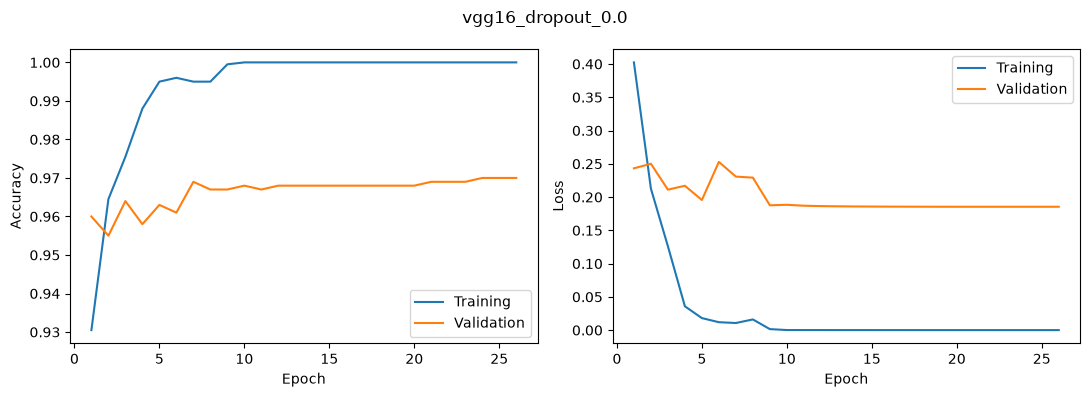

dropout_0.25 Validation: 95.70%, loss: 0.1589


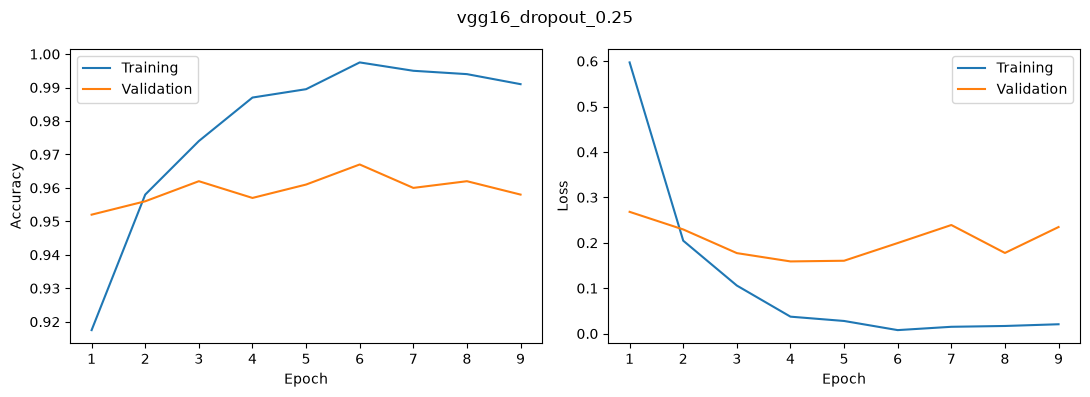

dropout_0.5 Validation: 97.00%, loss: 0.0916


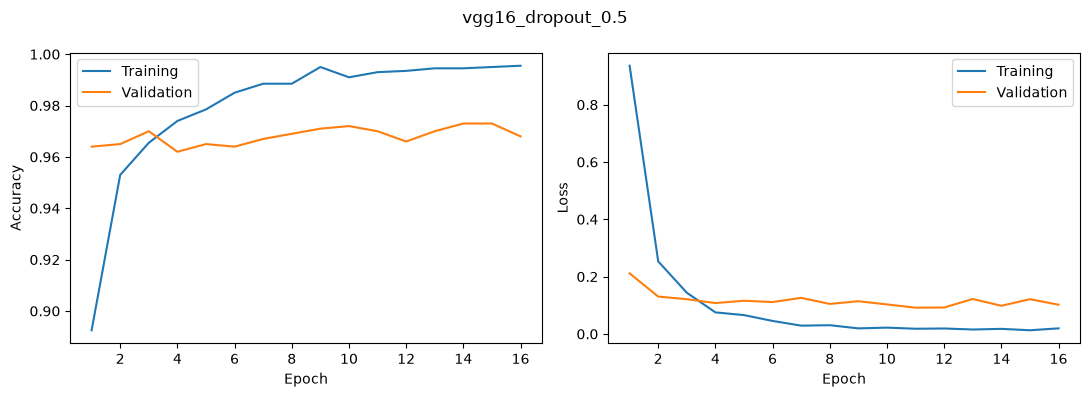

dropout_0.8 Validation: 96.70%, loss: 0.0696


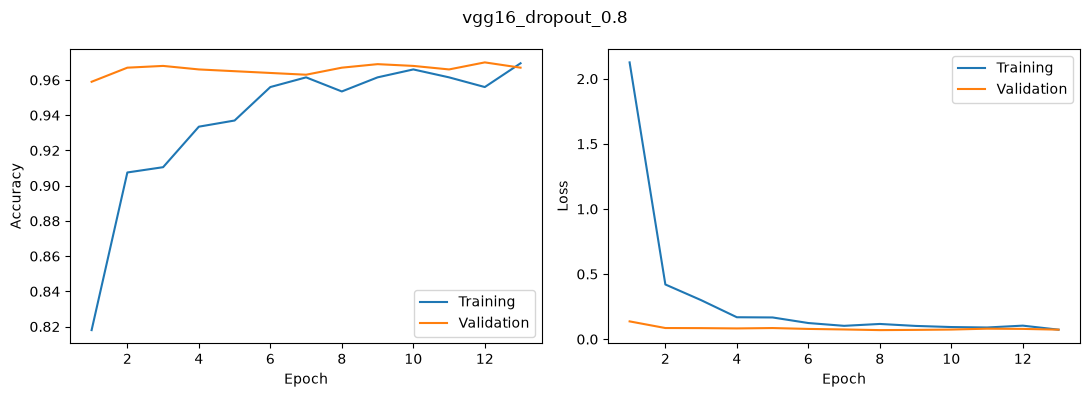

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,dropout_0.0,128,0.00,0,adam,0.001,30,25,26,21,8.599630,0.185407,0.969,1.0000
1,dropout_0.25,128,0.25,0,adam,0.001,30,25,9,4,4.300755,0.158931,0.957,0.9910
2,dropout_0.5,128,0.50,0,adam,0.001,30,25,16,11,6.089353,0.091584,0.970,0.9955
3,dropout_0.8,128,0.80,0,adam,0.001,30,25,13,8,5.319137,0.069597,0.967,0.9695


In [10]:
head_dir = DATA_ROOT / 'models' / 'lab8' / 'heads'
results = train_heads(features, labels, configs, NAME)
results.to_csv(f'results/{NAME}_experiments.csv', index=False)

In [ ]:
def assemble_model(base, results, model_name):
    best = results.sort_values('val_loss').iloc[0]
    config = {'name': model_name, 'size': SIZE, 'units': int(best['units']),
              'dropout': float(best['dropout']), 'extra_units': int(best['extra_units'])}
    head = keras.models.load_model(head_dir / f"{model_name}_{best['name']}.keras")
    inputs = keras.Input(shape=(SIZE, SIZE, 3))
    model = keras.Model(inputs, head(base(inputs, training=False)), name=model_name)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model, head, best, config

In [11]:
model, head, best, config = assemble_model(base, results, NAME)

## Results

In [12]:
test_loss, test_accuracy = model.evaluate(test_generator, verbose=0)
result = {'model': NAME, 'experiment': str(best['name']), 'val_loss': float(best['val_loss']),
          'val_accuracy': float(best['val_accuracy']), 'test_loss': test_loss,
          'test_accuracy': test_accuracy, 'parameters': model.count_params()}
display(pd.DataFrame([result]))
Path(f'results/{NAME}_metrics.json').write_text(json.dumps(result, indent=2))

,model,experiment,val_loss,val_accuracy,test_loss,test_accuracy,parameters
0,vgg16,dropout_0.8,0.069597,0.967,0.124012,0.957,14780481


227

## Saving

In [13]:
model_dir = DATA_ROOT / 'models' / 'lab8'
model.save(model_dir / f'{NAME}.keras')
save_bundle(model, base, head, f'models/{NAME}', config)
cache = DATA_ROOT / 'features' / f'{NAME}_{SIZE}'
cache.mkdir(parents=True, exist_ok=True)
for subset in features:
    np.save(cache / f'{subset}.npy', features[subset])

## New images

In [14]:
image_dir = Path('../lab7/images')
manifest = pd.DataFrame(json.loads((image_dir / 'manifest.json').read_text()))
images = []
for filename in manifest['file']:
    image = keras.utils.load_img(image_dir / filename, target_size=(SIZE, SIZE))
    images.append(keras.utils.img_to_array(image))
images = np.array(images)

In [ ]:
def predict_images(model, images, manifest, preprocess_input, name):
    probabilities = model.predict(preprocess_input(images.copy()), batch_size=16, verbose=0).ravel()
    new_results = manifest[['file', 'class']].copy()
    new_results['dog_probability'] = probabilities
    new_results['prediction'] = [classes[int(p >= 0.5)] for p in probabilities]
    new_results['correct'] = new_results['class'] == new_results['prediction']
    display(new_results)
    print('External accuracy:', f"{new_results['correct'].mean():.2%}")
    new_results.to_csv(f'results/{name}_external.csv', index=False)
    fig, axs = plt.subplots(4, 5, figsize=(14, 11))
    for ax, row in zip(axs.flat, new_results.itertuples()):
        ax.imshow(Image.open(image_dir / row.file))
        ax.set_title(f'{row[2]} --> {row.prediction}', fontsize=9,
                     color='green' if row.correct else 'red')
        ax.axis('off')
    plt.tight_layout()
    fig.savefig(f'results/{name}_external.png', dpi=150)
    plt.show()
    return new_results

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,7.691565e-07,cat,True
1,cat_02.jpg,cat,8.371764e-01,dog,False
2,cat_03.jpg,cat,5.916888e-01,dog,False
3,cat_04.jpg,cat,3.846489e-01,cat,True
4,cat_05.jpg,cat,7.362575e-01,dog,False
5,dog_01.jpg,dog,9.989674e-01,dog,True
6,dog_02.jpg,dog,9.841198e-01,dog,True
7,dog_03.jpg,dog,9.999760e-01,dog,True
8,dog_04.jpg,dog,9.900424e-01,dog,True
9,dog_05.jpg,dog,7.093441e-01,dog,True


External accuracy: 70.00%


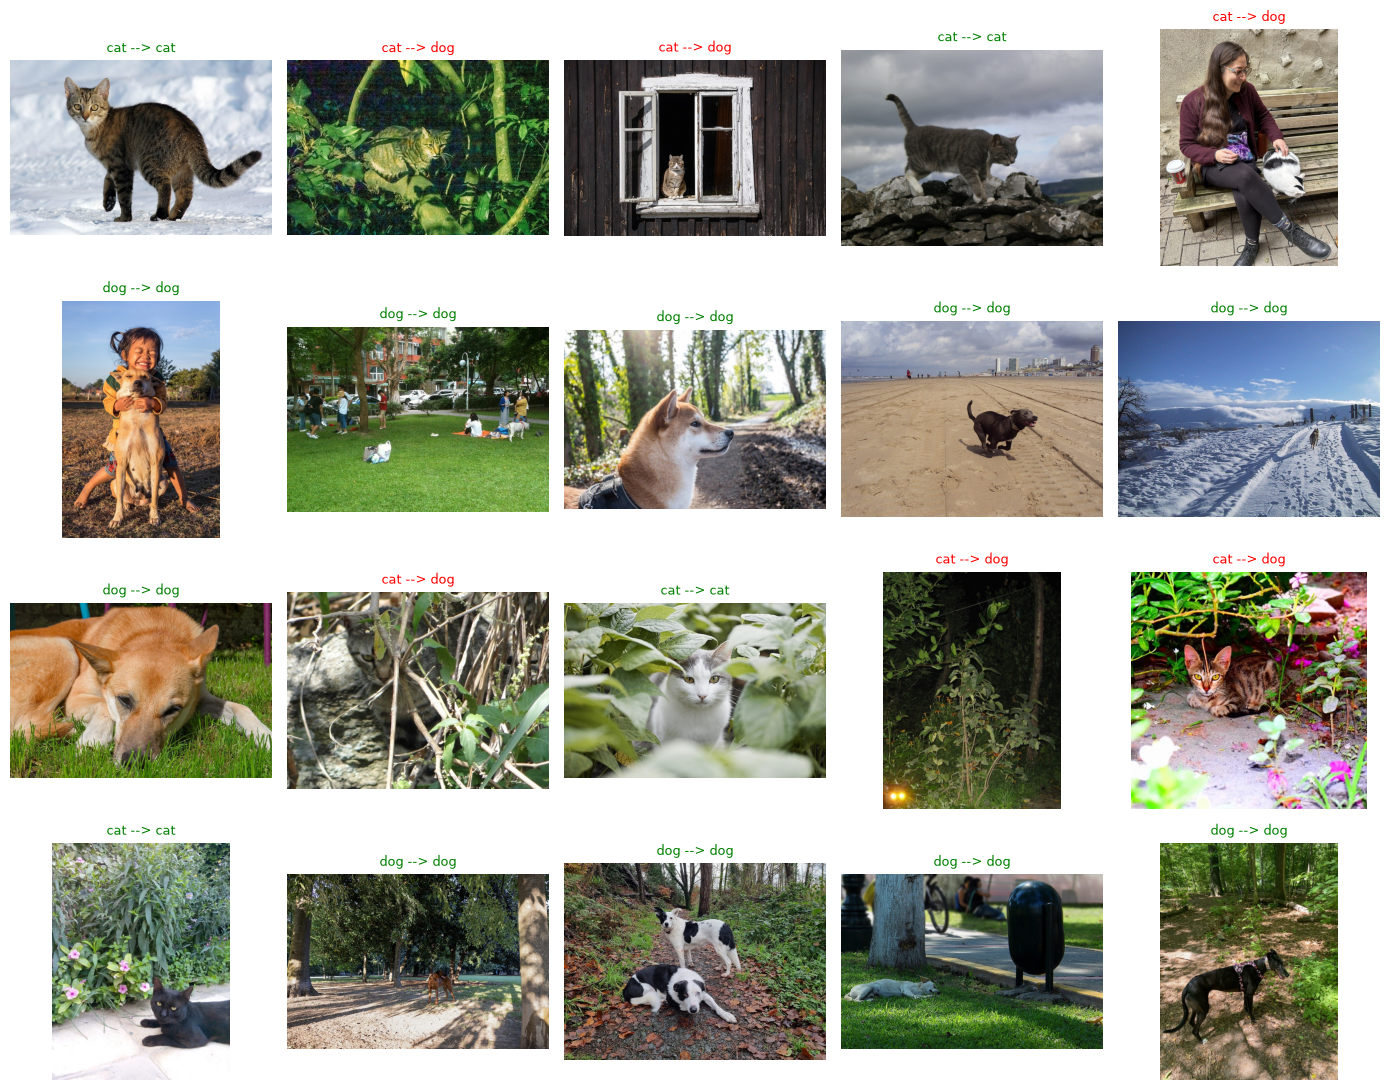

In [15]:
new_results = predict_images(model, images, manifest, preprocess_input, NAME)

In [ ]:
del model, base, head
keras.backend.clear_session()

# ResNet50

## Data

In [ ]:
NAME = 'resnet50'
preprocess_input = keras.applications.resnet50.preprocess_input

In [4]:
train_generator, validation_generator, test_generator = make_generators(preprocess_input)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
base = keras.applications.ResNet50(
    weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3), pooling='avg')
base.trainable = False
print('Base parameters:', base.count_params())
print('Trainable base weights:', len(base.trainable_weights))

       0/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/94765736 ━━━━━━━━━━━━━━━━━━━━ 4:21 3us/step

   81920/94765736 ━━━━━━━━━━━━━━━━━━━━ 4:53 3us/step

  147456/94765736 ━━━━━━━━━━━━━━━━━━━━ 3:21 2us/step

  212992/94765736 ━━━━━━━━━━━━━━━━━━━━ 2:46 2us/step

  278528/94765736 ━━━━━━━━━━━━━━━━━━━━ 2:26 2us/step

... (54 outputs left out)

92626944/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

93618176/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Base parameters: 23587712
Trainable base weights: 0


In [6]:
features, labels = extract_features(base, train_generator, validation_generator)

train (2000, 2048)


validation (1000, 2048)


## Training

dropout_0.0 Validation: 97.20%, loss: 0.0676


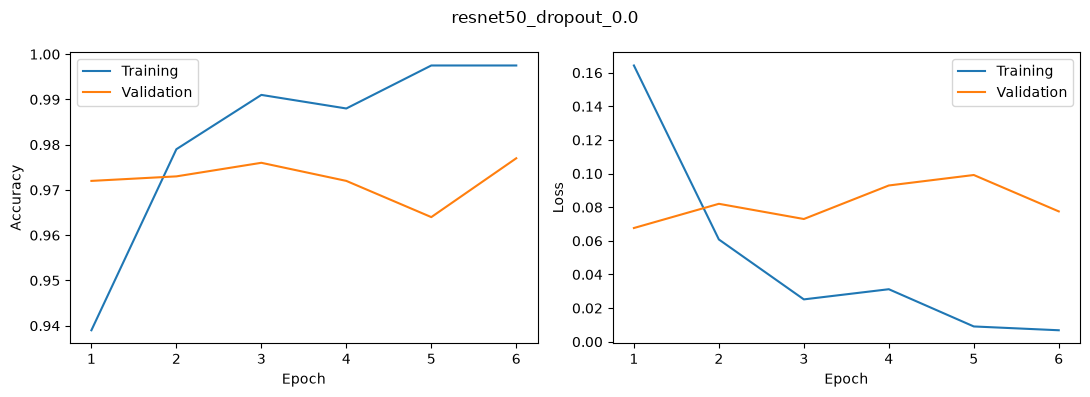

dropout_0.25 Validation: 97.50%, loss: 0.0693


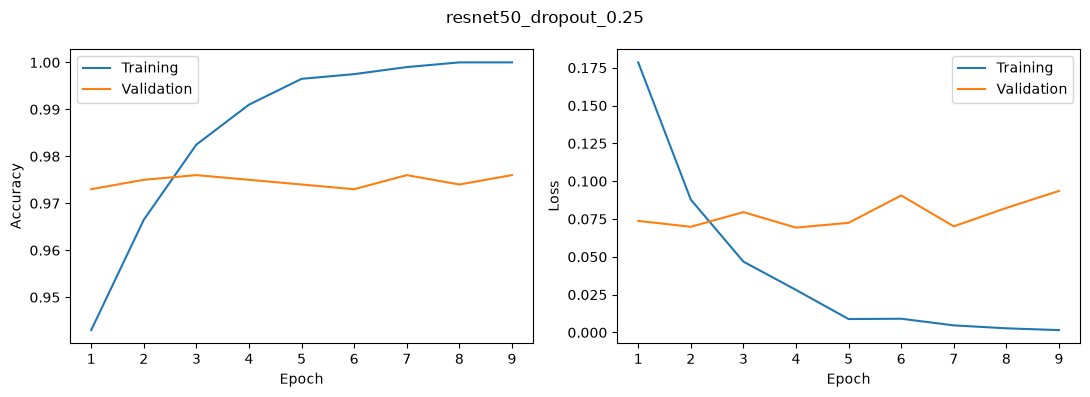

dropout_0.5 Validation: 97.60%, loss: 0.0583


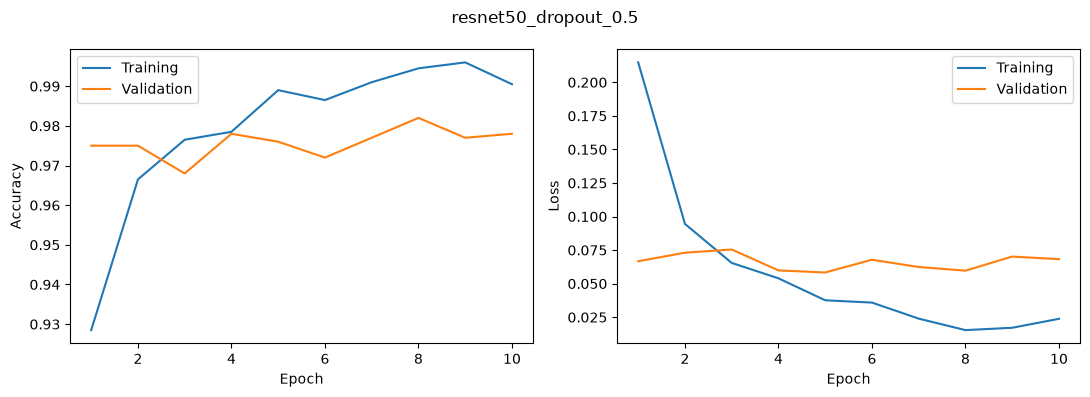

dropout_0.8 Validation: 97.90%, loss: 0.0513


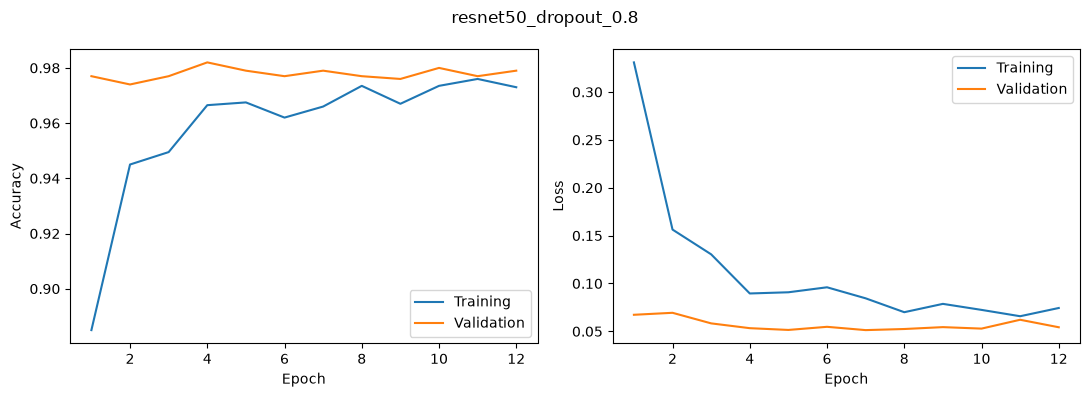

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,dropout_0.0,128,0.00,0,adam,0.001,30,25,6,1,3.924126,0.067629,0.972,0.9975
1,dropout_0.25,128,0.25,0,adam,0.001,30,25,9,4,4.806524,0.069293,0.975,1.0000
2,dropout_0.5,128,0.50,0,adam,0.001,30,25,10,5,4.851400,0.058305,0.976,0.9905
3,dropout_0.8,128,0.80,0,adam,0.001,30,25,12,7,5.320789,0.051291,0.979,0.9730


In [10]:
head_dir = DATA_ROOT / 'models' / 'lab8' / 'heads'
results = train_heads(features, labels, configs, NAME)
results.to_csv(f'results/{NAME}_experiments.csv', index=False)

In [11]:
model, head, best, config = assemble_model(base, results, NAME)

## Results

In [12]:
test_loss, test_accuracy = model.evaluate(test_generator, verbose=0)
result = {'model': NAME, 'experiment': str(best['name']), 'val_loss': float(best['val_loss']),
          'val_accuracy': float(best['val_accuracy']), 'test_loss': test_loss,
          'test_accuracy': test_accuracy, 'parameters': model.count_params()}
display(pd.DataFrame([result]))
Path(f'results/{NAME}_metrics.json').write_text(json.dumps(result, indent=2))

,model,experiment,val_loss,val_accuracy,test_loss,test_accuracy,parameters
0,resnet50,dropout_0.8,0.051291,0.979,0.076201,0.966,23850113


230

## Saving

In [13]:
model_dir = DATA_ROOT / 'models' / 'lab8'
model.save(model_dir / f'{NAME}.keras')
save_bundle(model, base, head, f'models/{NAME}', config)
cache = DATA_ROOT / 'features' / f'{NAME}_{SIZE}'
cache.mkdir(parents=True, exist_ok=True)
for subset in features:
    np.save(cache / f'{subset}.npy', features[subset])

## New images

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,0.181556,cat,True
1,cat_02.jpg,cat,0.784527,dog,False
2,cat_03.jpg,cat,0.605673,dog,False
3,cat_04.jpg,cat,0.283384,cat,True
4,cat_05.jpg,cat,0.360751,cat,True
5,dog_01.jpg,dog,1.000000,dog,True
6,dog_02.jpg,dog,0.997033,dog,True
7,dog_03.jpg,dog,0.999551,dog,True
8,dog_04.jpg,dog,0.973183,dog,True
9,dog_05.jpg,dog,0.454590,cat,False


External accuracy: 75.00%


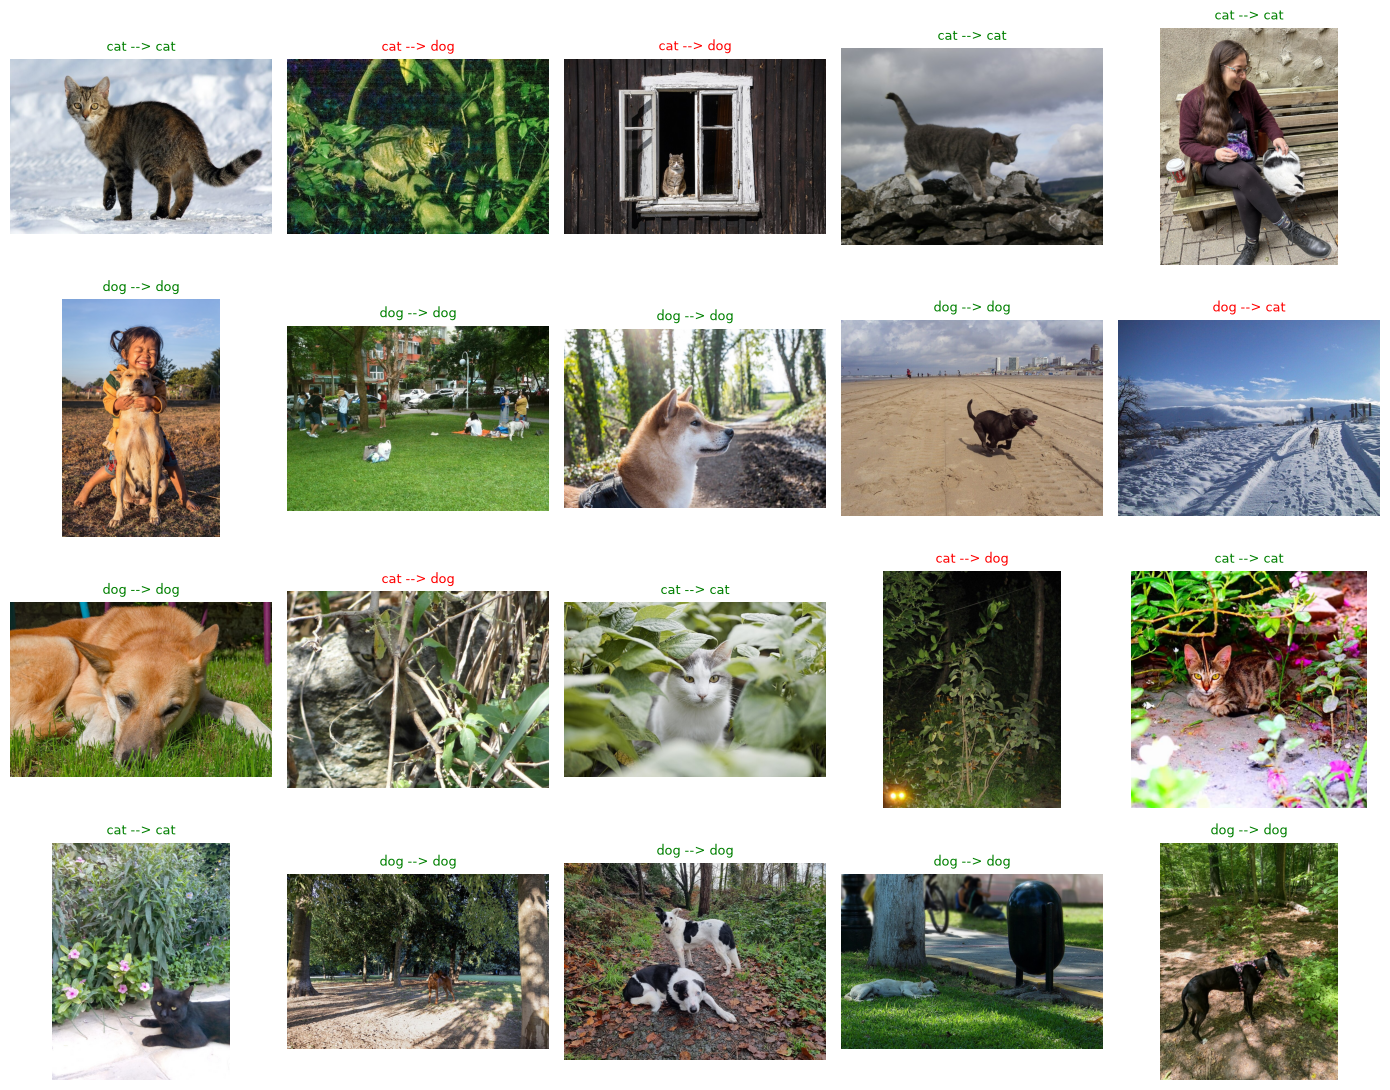

In [15]:
new_results = predict_images(model, images, manifest, preprocess_input, NAME)

In [ ]:
del model, base, head
keras.backend.clear_session()

# InceptionV3

## Data

In [ ]:
NAME = 'inception_v3'
preprocess_input = keras.applications.inception_v3.preprocess_input

In [4]:
train_generator, validation_generator, test_generator = make_generators(preprocess_input)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
base = keras.applications.InceptionV3(
    weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3), pooling='avg')
base.trainable = False
print('Base parameters:', base.count_params())
print('Trainable base weights:', len(base.trainable_weights))

       0/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/87910968 ━━━━━━━━━━━━━━━━━━━━ 4:01 3us/step

   81920/87910968 ━━━━━━━━━━━━━━━━━━━━ 4:32 3us/step

  147456/87910968 ━━━━━━━━━━━━━━━━━━━━ 3:05 2us/step

  212992/87910968 ━━━━━━━━━━━━━━━━━━━━ 2:33 2us/step

  278528/87910968 ━━━━━━━━━━━━━━━━━━━━ 2:14 2us/step

... (62 outputs left out)

86695936/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

87392256/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Base parameters: 21802784
Trainable base weights: 0


In [6]:
features, labels = extract_features(base, train_generator, validation_generator)

train (2000, 2048)


validation (1000, 2048)


## Training

dropout_0.0 Validation: 96.00%, loss: 0.1230


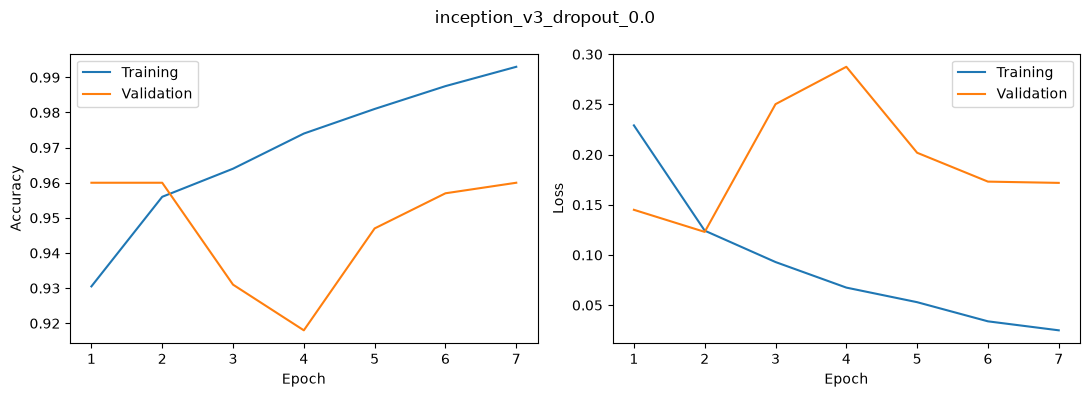

dropout_0.25 Validation: 96.40%, loss: 0.1096


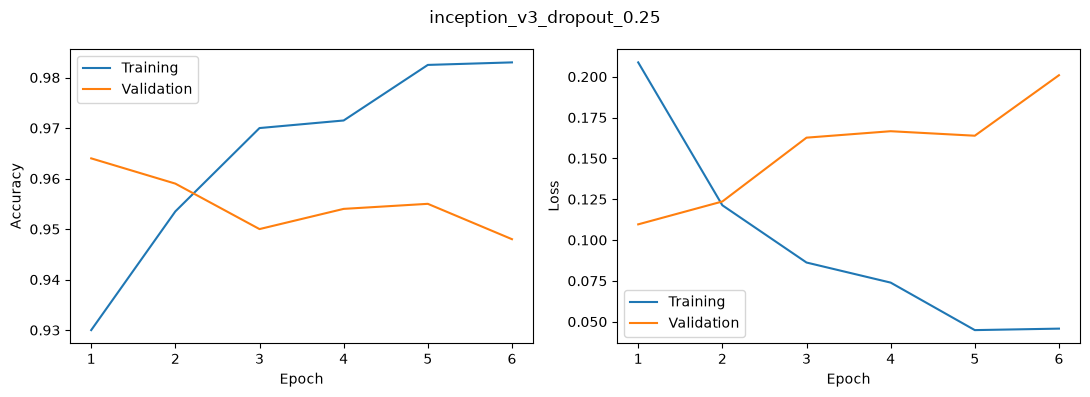

dropout_0.5 Validation: 96.80%, loss: 0.1052


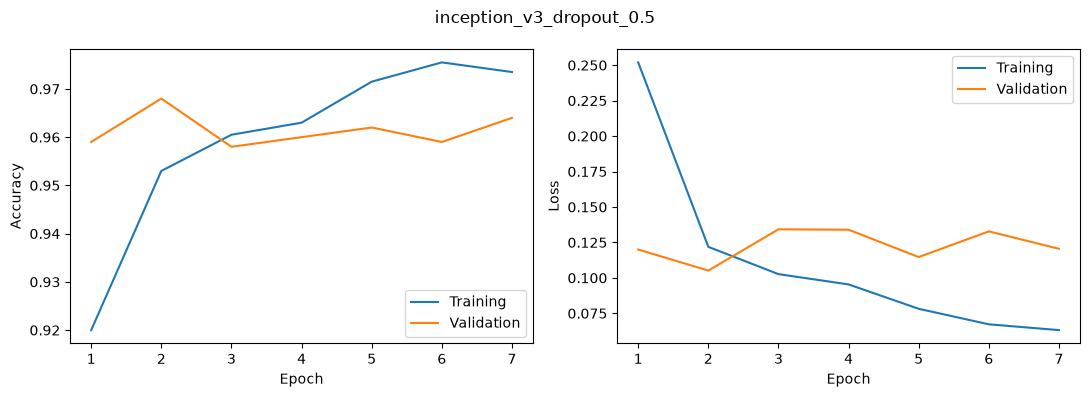

dropout_0.8 Validation: 96.80%, loss: 0.0944


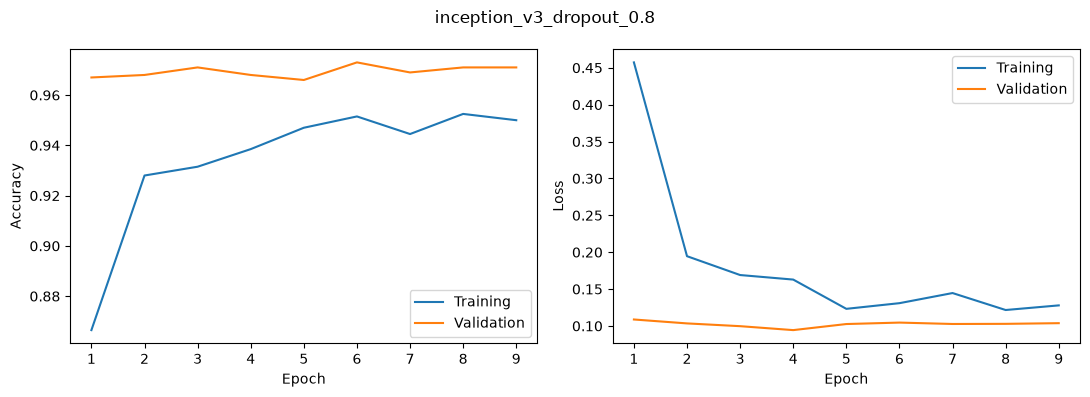

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,dropout_0.0,128,0.00,0,adam,0.001,30,25,7,2,4.381423,0.122988,0.960,0.9930
1,dropout_0.25,128,0.25,0,adam,0.001,30,25,6,1,4.009938,0.109582,0.964,0.9830
2,dropout_0.5,128,0.50,0,adam,0.001,30,25,7,2,3.904108,0.105163,0.968,0.9735
3,dropout_0.8,128,0.80,0,adam,0.001,30,25,9,4,4.476674,0.094361,0.968,0.9500


In [10]:
head_dir = DATA_ROOT / 'models' / 'lab8' / 'heads'
results = train_heads(features, labels, configs, NAME)
results.to_csv(f'results/{NAME}_experiments.csv', index=False)

In [11]:
model, head, best, config = assemble_model(base, results, NAME)

## Results

In [12]:
test_loss, test_accuracy = model.evaluate(test_generator, verbose=0)
result = {'model': NAME, 'experiment': str(best['name']), 'val_loss': float(best['val_loss']),
          'val_accuracy': float(best['val_accuracy']), 'test_loss': test_loss,
          'test_accuracy': test_accuracy, 'parameters': model.count_params()}
display(pd.DataFrame([result]))
Path(f'results/{NAME}_metrics.json').write_text(json.dumps(result, indent=2))

,model,experiment,val_loss,val_accuracy,test_loss,test_accuracy,parameters
0,inception_v3,dropout_0.8,0.094361,0.968,0.094902,0.963,22065185


234

## Saving

In [13]:
model_dir = DATA_ROOT / 'models' / 'lab8'
model.save(model_dir / f'{NAME}.keras')
save_bundle(model, base, head, f'models/{NAME}', config)
cache = DATA_ROOT / 'features' / f'{NAME}_{SIZE}'
cache.mkdir(parents=True, exist_ok=True)
for subset in features:
    np.save(cache / f'{subset}.npy', features[subset])

## New images

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,0.019005,cat,True
1,cat_02.jpg,cat,0.499619,cat,True
2,cat_03.jpg,cat,0.780210,dog,False
3,cat_04.jpg,cat,0.236677,cat,True
4,cat_05.jpg,cat,0.588517,dog,False
5,dog_01.jpg,dog,0.999294,dog,True
6,dog_02.jpg,dog,0.863268,dog,True
7,dog_03.jpg,dog,0.727811,dog,True
8,dog_04.jpg,dog,0.800416,dog,True
9,dog_05.jpg,dog,0.584306,dog,True


External accuracy: 80.00%


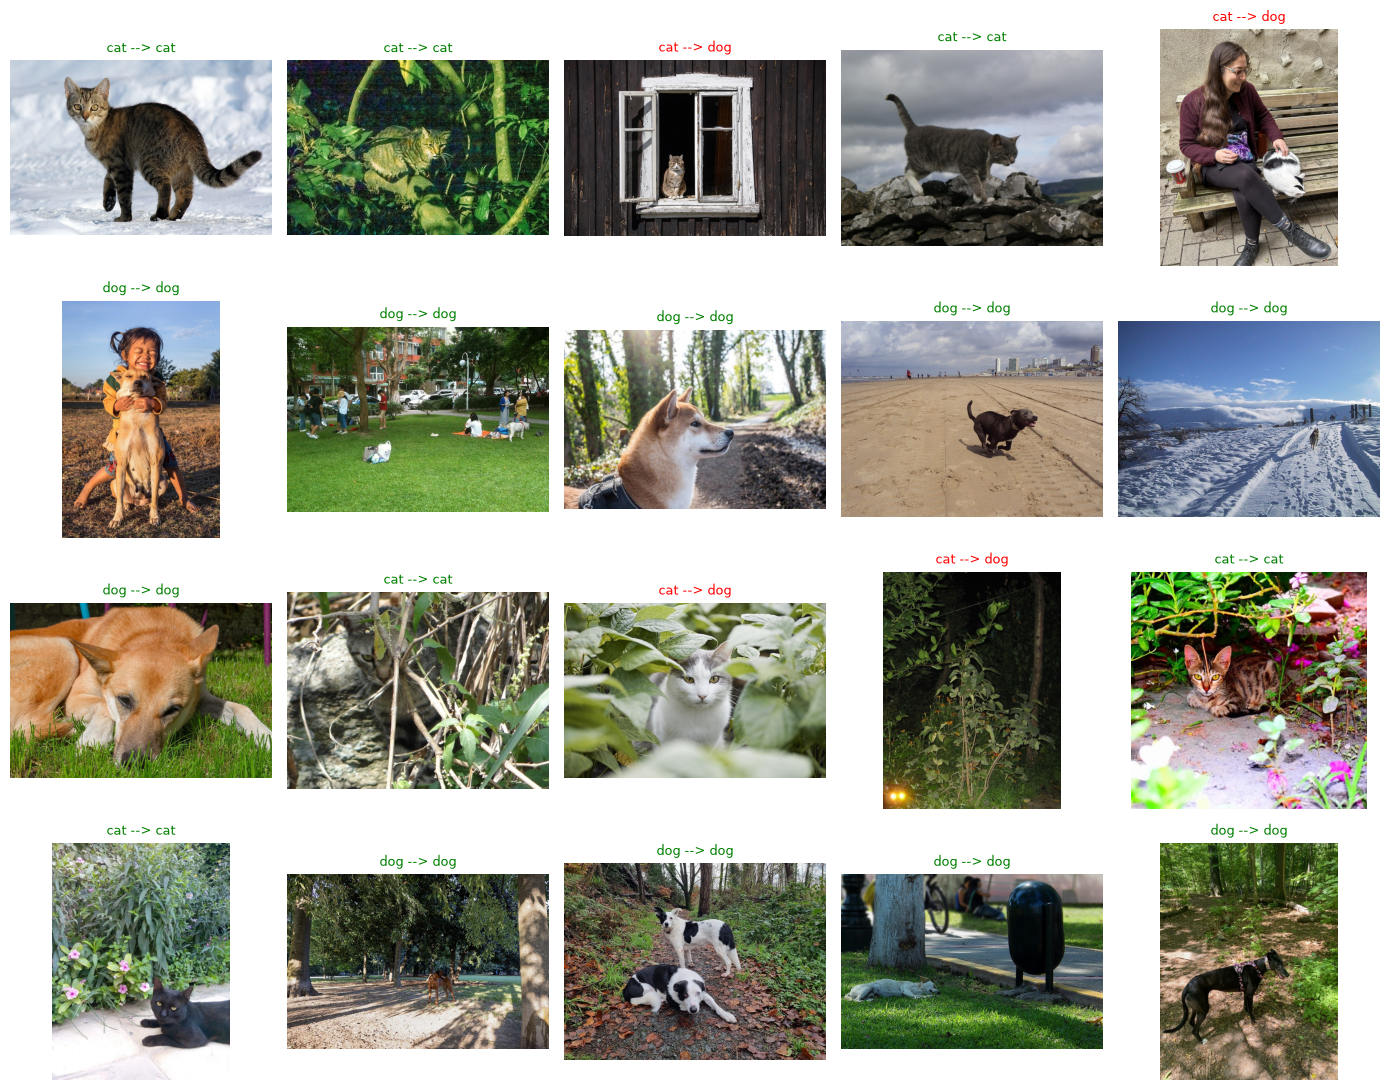

In [15]:
new_results = predict_images(model, images, manifest, preprocess_input, NAME)

In [ ]:
del model, base, head
keras.backend.clear_session()

# Comparison

In [17]:
rows = []
cnn = json.loads(Path('../lab7/results/cats_metrics.json').read_text())
cnn_external = pd.read_csv('../lab7/results/cats_external.csv')
rows.append({'model': 'cnn', 'stage': 'from_scratch', 'val_accuracy': cnn['val_accuracy'],
             'test_accuracy': cnn['test_accuracy'], 'external_accuracy': cnn_external['correct'].mean()})
for stage, folder in [('transfer', '../lab8')]:
    for name in ['vgg16', 'resnet50', 'inception_v3']:
        metrics = json.loads((Path(folder) / 'results' / f'{name}_metrics.json').read_text())
        external = pd.read_csv(Path(folder) / 'results' / f'{name}_external.csv')
        rows.append({'model': name, 'stage': stage, 'val_accuracy': metrics['val_accuracy'],
                     'test_accuracy': metrics['test_accuracy'],
                     'external_accuracy': external['correct'].mean()})
comparison = pd.DataFrame(rows)
comparison.to_csv('results/comparison.csv', index=False)
display(comparison)


,model,stage,val_accuracy,test_accuracy,external_accuracy
0,cnn,from_scratch,0.753,0.777,0.45
1,vgg16,transfer,0.967,0.957,0.70
2,resnet50,transfer,0.979,0.966,0.75
3,inception_v3,transfer,0.968,0.963,0.80


# Summary

## VGG16

Використано vgg16 з вагами ImageNet та замороженою згортковою частиною. Вхід - RGB 150x150; застосовано preprocess_input саме цієї архітектури до пікселів [0, 255]. Додано Dense(128), Dropout і один sigmoid-вихід. Навчалися лише ваги класифікатора; заморожені ознаки кешовано для повторного використання.

Перевірено чотири значення Dropout на тому самому поділі з лабораторної 7. Кожен запуск починався з однакового seed; рання зупинка повертала ваги з найменшими валідаційними втратами.

| Dropout | Validation accuracy | Validation loss | Best epoch |
|---|---:|---:|---:|
| 0 | 96.90% | 0.1854 | 21 |
| 0.25 | 95.70% | 0.1589 | 4 |
| 0.5 | 97.00% | 0.0916 | 11 |
| 0.8 | 96.70% | 0.0696 | 8 |

За валідаційними втратами обрано **dropout_0.8**: валідаційна точність **96.70%**, тестова - **95.70%**, точність на 20 зовнішніх фото - **70.00%**. Графіки навчання та валідації дозволяють оцінити перенавчання; більше Dropout не обов'язково дає кращий результат. Зовнішні фото не використовувалися для вибору конфігурації.

Повну модель збережено поза Git. У репозиторії є навчені ваги класифікатора, параметри архітектури та код відновлення з ImageNet. 

## ResNet50

Використано resnet50 з вагами ImageNet та замороженою згортковою частиною. Вхід - RGB 150x150; застосовано preprocess_input саме цієї архітектури до пікселів [0, 255]. Додано Dense(128), Dropout і один sigmoid-вихід. Навчалися лише ваги класифікатора; заморожені ознаки кешовано для повторного використання.

Перевірено чотири значення Dropout на тому самому поділі з лабораторної 7. Кожен запуск починався з однакового seed; рання зупинка повертала ваги з найменшими валідаційними втратами.

| Dropout | Validation accuracy | Validation loss | Best epoch |
|---|---:|---:|---:|
| 0 | 97.20% | 0.0676 | 1 |
| 0.25 | 97.50% | 0.0693 | 4 |
| 0.5 | 97.60% | 0.0583 | 5 |
| 0.8 | 97.90% | 0.0513 | 7 |

За валідаційними втратами обрано **dropout_0.8**: валідаційна точність **97.90%**, тестова - **96.60%**, точність на 20 зовнішніх фото - **75.00%**. Графіки навчання та валідації дозволяють оцінити перенавчання; більше Dropout не обов'язково дає кращий результат. Зовнішні фото не використовувалися для вибору конфігурації.

Повну модель збережено поза Git. У репозиторії є навчені ваги класифікатора, параметри архітектури та код відновлення з ImageNet. 

## InceptionV3

Використано inception_v3 з вагами ImageNet та замороженою згортковою частиною. Вхід - RGB 150x150; застосовано preprocess_input саме цієї архітектури до пікселів [0, 255]. Додано Dense(128), Dropout і один sigmoid-вихід. Навчалися лише ваги класифікатора; заморожені ознаки кешовано для повторного використання.

Перевірено чотири значення Dropout на тому самому поділі з лабораторної 7. Кожен запуск починався з однакового seed; рання зупинка повертала ваги з найменшими валідаційними втратами.

| Dropout | Validation accuracy | Validation loss | Best epoch |
|---|---:|---:|---:|
| 0 | 96.00% | 0.1230 | 2 |
| 0.25 | 96.40% | 0.1096 | 1 |
| 0.5 | 96.80% | 0.1052 | 2 |
| 0.8 | 96.80% | 0.0944 | 4 |

За валідаційними втратами обрано **dropout_0.8**: валідаційна точність **96.80%**, тестова - **96.30%**, точність на 20 зовнішніх фото - **80.00%**. Графіки навчання та валідації дозволяють оцінити перенавчання; більше Dropout не обов'язково дає кращий результат. Зовнішні фото не використовувалися для вибору конфігурації.

Повну модель збережено поза Git. У репозиторії є навчені ваги класифікатора, параметри архітектури та код відновлення з ImageNet. 